Ivan Montes  22 Oct 2026
SIO-221A

Soltuions: At a Glance.

1.Visual evaluation. Plot the time series of wind speed, wave height, water temperature, and air temperature from 46047. Since the data are text files with a header, in Matlab you can read with: Read the help page. You’ll want to specify a blank space delimiter between files and 2 header lines. How are missing data identified in the records?
    
    I added a float for the headers, and I got NaNs for some of the data; I was scrolling the data, It wasn't obvious at first so I had to go back and code in a count for the missing data; that allowed me to see there was +400 points of missing data, including the NaNs. mostly in the Wave Height data set. I plotted the missing data separately so it can be compare to the time series. The data that is there shows the seasonal cycle although it is a bit noisy.


2.Monthly means. Since there’s quite a bit of variability, average the data to produce monthly means for 2015 and 2016. Plot the means for each month and
standard error of the mean. Data are provided at varying frequencies, but consecutive data are not independent. For the purposes of this problem set, let’s assume that the data provide one independent sample every 7 days. error bar to plot the data with uncertainty ranges.

    There is a wide range of uncertainty, which I think is coming from variability/seasonal cycles, 2015-2016 was also an el nino year so it good to note that as well, which might make sense of high temps in air and water. in the graph both wind speed and wave height have a wide variability in the beginning and end of the year;. wind speed seems to have a less obvious sin wave than the others, although you can still make it out. The Temp seems to be consistent with seasonal cycles, and as of now I haven't be able to clearly see the wave heigh pattern outside of it general Sin shape.

    From the numbers when we switched to being sampled every 7 days it actually made the error bar much bigger, being the largest at the wave hight and wind during the winter. July, was the hottest water temp, my speculation is that that might have been a combination from the ENSO and summer temps.


3.Least-squares fit. Treating the two years separately, least-squares fit a mean and an annual cycle to the four data records. What is the mean, and what is the amplitude of the annual cycle? (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.) Are the fitted coefficients similar for the two years?

    Looking at the annual cycle Amplitudes wind Speed mean and amp is within 1-Sigma. Meaning that that is expected and there is no variable cycle we are looking at here. But, Wave height and temperature do in fact have a annual cycle of note. When I compare the 2-years they do not appear similar. the amplitudes overall are far too different to say it was the same. This makes since since ENSO was that year, and there may have been more other factors but that is a large one; for this year anyways.


4.Least-squares fit a semi-annual cycle. Augment your annual cycle least squares fit with a semi-annual cycle. What is the amplitude of the semi-annual
cycle? Does the augmented fit give you a different annual cycle?
    
    I am not sure if I should have gotten a better fit, by adding the 6-month period or 2x frequency I was expecting to see a stronger response from the wave height. Given the example we did in class. Although the shape seems to go with the points It does not match as well as expected but the shape did improve a bit although there is a slight shift to the left.


5.χ2 and the misfit. What is the squared misfit of your least-squares fits? You can compute this as χ2 =N∑i=1(yi − ∑Mj=1 aij xj )2σ2i∼ N − M1
In other words, the misfit for each point should be roughly equal to the uncertainty. We lose a degree of freedom for each function that we use to fit. How much? does the misfit change if you fit with an annual cycle only or with an annual plus semi-annnual cycle? Use the χ2 distribution to evaluate whether your fits are improved by adding the semi-annual fit? On the basis of the χ2 distribution, are you overfitting the data, or choosing the wrong model for your data? How would your results change if you assumed that you had one independent sample (i.e. one degree of freedom) per day, instead of one per week?
    
    I think wind and wave fit well; but, because of the variability of the temp the analysis didn't account well perhaps if i had used the 4-years instead of just the two years I would have gotten a better result; like it was said more data is the key. I think this would using the wrong model in this case one that accounts for ENSO would have been the right choice. I think using 1 sample a day the error bars would haven gotten much larger; but the wave function perhaps would have fit better but more errors. 



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

years = [2015, 2016]
# I need to add somehting here, for the Nans;s going to but some missing label.
missing = {'WSPD': 99.0, 'WVHT': 99.0, 'WTMP': 999.0, 'ATMP': 999.0}
labels  = {'WSPD': 'wind speed (m/s)', 'WVHT': 'wave height (m)',
           'WTMP': 'water temp (°C)', 'ATMP': 'air temp (°C)'}

def load_year(fname):
    #adding float. 
    df = pd.read_csv(fname, sep=r'\s+', skiprows=[1])
    df = df.rename(columns={'#YY': 'year', 'MM': 'month', 'DD': 'day',
                            'hh': 'hour', 'mm': 'minute'})
    for v, bad in missing.items():
        df[v] = df[v].replace(bad, np.nan)   # flagged values become NaN
    return df

Problem 1 Troubleshooting
    In loading the data, I am getting an huge error I am not sure how to fix this and I havent seen this before, file/lineerror. I am going to trouble shoot this below. Adding a code to fix. I am going to try to call the data I am still not completely sure how to do this on github so I had to research this a bit. I hope this doesn't break anything that is my biggest worry. 

In [4]:
import os
print(os.getcwd())
print(os.listdir('.'))

c:\Users\IvanM\OneDrive\Documents\GitHub\SIO221a_Github_code_2026\homework
['HW5_data', 'IvanMontes_Hw03.ipynb']


In [ ]:
import os, urllib.request

data_folder = 'data_46047'
os.makedirs(data_folder, exist_ok=True)

def get_year(yr):
    fname = os.path.join(data_folder, f'46047h{yr}.txt.gz')
    if not os.path.isfile(fname):         
        url = f'https://www.ndbc.noaa.gov/data/historical/stdmet/46047h{yr}.txt.gz'
        print('downloading', url)
        urllib.request.urlretrieve(url, fname)
    return fname

monthly = {}
for yr in years:
    df = load_year(get_year(yr))     
    g = df.groupby('month')
    monthly[yr] = {}
    for v in missing:
        mean = g[v].mean()
        std  = g[v].std(ddof=1)
        n    = g[v].count()
        monthly[yr][v] = pd.DataFrame({'mean': mean,
                                       'sem': std/np.sqrt(n),
                                       'n': n}).dropna()

I adjusted this above to pull the NOAA data set and make a file for it as mentioned above. Now that the data is downloaded; I am going to check it to see if I have any missing data. I want sure how to tell so I am going to include a count missing data point count at the end of this. so I can see what that actually looks like.

In [16]:
for yr in years:
    for v in missing:
        print(yr, v)
        print(monthly[yr][v].round(3).T)
        print()
raw = pd.read_csv(get_year(2015), sep=r'\s+', skiprows=[1])
print(raw[['WSPD', 'WVHT', 'WTMP', 'ATMP']].describe().loc[['count', 'min', 'max']])

flags = {'WSPD': 99.0, 'WVHT': 99.0, 'WTMP': 999.0, 'ATMP': 999.0}
for v, f in flags.items():
    print(v, 'flagged points:', int((raw[v] == f).sum()), 'of', len(raw))

2015 WSPD
month      1        2        3        4        5        6        7        8   \
mean     3.92    5.184    5.678    7.075    7.033    6.863    5.102    7.254   
sem      0.08    0.100    0.094    0.112    0.069    0.081    0.084    0.096   
n      743.00  671.000  743.000  718.000  744.000  719.000  743.000  743.000   

month       9        10       11       12  
mean     5.307    6.271    6.045    8.137  
sem      0.084    0.105    0.125    0.123  
n      718.000  744.000  719.000  741.000  

2015 WVHT
month       1        2        3        4        5        6        7        8   \
mean     1.813    1.944    1.781    2.418    1.914    1.698    1.413    1.582   
sem      0.024    0.026    0.020    0.030    0.021    0.014    0.013    0.015   
n      726.000  649.000  722.000  667.000  707.000  687.000  725.000  701.000   

month       9        10       11       12  
mean     1.637    2.069    2.287    3.130  
sem      0.011    0.022    0.036    0.044  
n      707.000  712.000  

OKay now that I can see that there are some points missing; it still doesn't tell where, what year dates are missing.

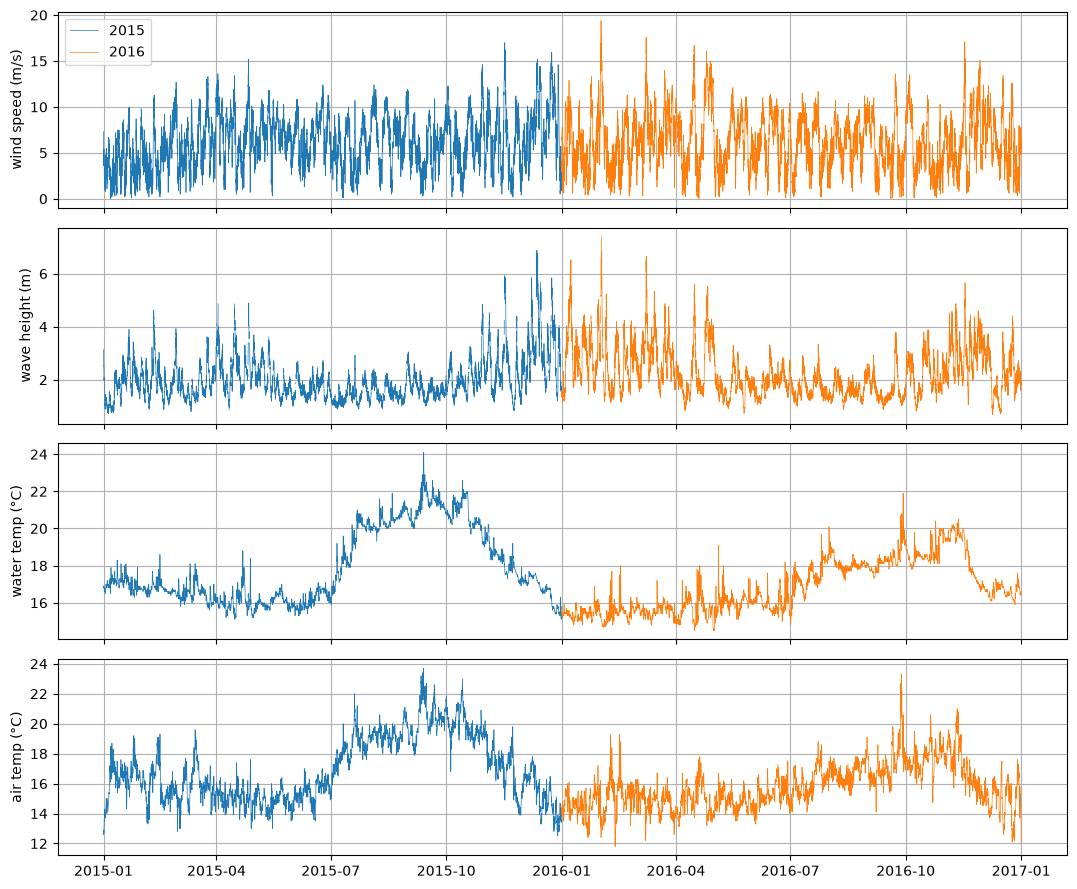

In [17]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, v in zip(axes, missing):
    for yr in years:
        d = load_year(get_year(yr))          # flags already replaced by NaN
        t = pd.to_datetime(d[['year', 'month', 'day', 'hour', 'minute']])
        ax.plot(t, d[v], lw=0.5, label=str(yr))
    ax.set_ylabel(labels[v]); ax.grid(True)
axes[0].legend()
plt.tight_layout(); plt.show()

I still cant tell where gaps exisit so I will only plot the missing data to understand this better. Air temp seems to vary quite a bit from 2015 to 2016 as well as the water temp going really high in 2015 as compared to 2016.

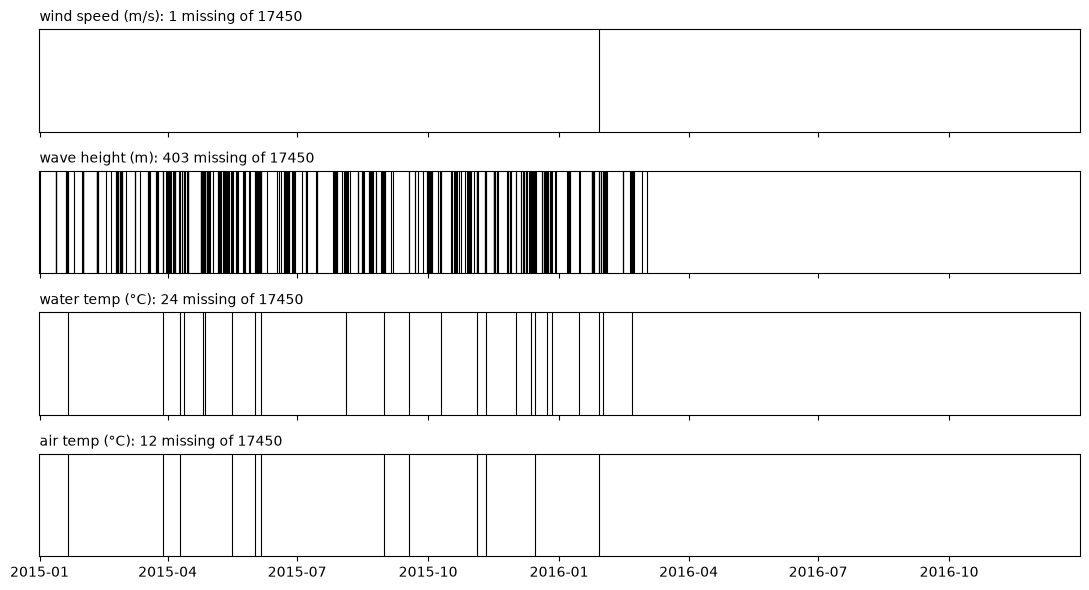

In [ ]:
# Stack both years into one table with a proper time column
frames = []
for yr in years:
    d = load_year(get_year(yr))          .
    d['time'] = pd.to_datetime(d[['year', 'month', 'day', 'hour', 'minute']])
    frames.append(d)
allD = pd.concat(frames, ignore_index=True)

fig, axes = plt.subplots(4, 1, figsize=(11, 6), sharex=True)
for ax, v in zip(axes, missing):
    tmiss = allD.loc[allD[v].isna(), 'time']      # times where this variable is missing
    ax.vlines(tmiss, 0, 1, color='k', lw=0.8)     # one black line per missing point
    ax.set_ylim(0, 1)
    ax.set_yticks([])                             # no y-axis needed, it's just present/absent
    ax.set_xlim(allD['time'].min(), allD['time'].max())
    ax.set_title(f'{labels[v]}: {len(tmiss)} missing of {len(allD)}',
                 loc='left', fontsize=10)
plt.tight_layout()
plt.show()

Solution For problem 1
    I added a float for the headers, and I got NaNs for some of the data; I was scrolling the data, It wasn't obvious at first so I had to go back and code in a count for the missing data; that allowed me to see there was +400 points of missing data, including the NaNs. mostly in the Wave Height data set. I plotted the missing data separately so it can be compare to the time series. The data that is there shows the seasonal cycle although it is a bit noisy. I also added the missing data points as a bar graph for a visual.

Starting on problem 2. Next is to determine the monthly mean as we mentioned in class that we need to do this instead of of using all data points. I will take the monthly mean then, use the least sq formula, then print to see what those results are. I need to code from Lecture 4, I will use the formula needed and plot the STD error of the mean. 

In [ ]:
import calendar

monthly = {}
for yr in years:
    df = load_year(get_year(yr))
    g = df.groupby('month')
    days = pd.Series({m: calendar.monthrange(yr, m)[1] for m in range(1, 13)})
    monthly[yr] = {}
    for v in missing: #std error coding 
        mean = g[v].mean()
        std  = g[v].std(ddof=1)
        n    = g[v].count()
        d    = days.loc[mean.index]
        monthly[yr][v] = pd.DataFrame({
            'mean': mean, 'std': std, 'n': n,
            'sem_weekly': std / np.sqrt(d / 7),   # 1 independent sample per 7 days
            'sem_daily':  std / np.sqrt(d),       # 1 per day 
            'sem_all':    std / np.sqrt(n),       # every valid sample treated as independent
        }).dropna()

Need to see what these numbers are printing now.

In [23]:
print(monthly[2015]['WTMP'].round(3).T)

month            1        2        3        4        5        6        7   \
mean         17.029   16.736   16.454   16.070   16.039   16.154   18.776   
std           0.339    0.287    0.445    0.597    0.319    0.431    1.333   
n           742.000  671.000  742.000  714.000  743.000  717.000  743.000   
sem_weekly    0.161    0.143    0.212    0.288    0.151    0.208    0.633   
sem_daily     0.061    0.054    0.080    0.109    0.057    0.079    0.239   
sem_all       0.012    0.011    0.016    0.022    0.012    0.016    0.049   

month            8        9        10       11       12  
mean         20.438   21.312   20.697   18.228   16.652  
std           0.412    0.687    0.750    0.741    0.709  
n           741.000  717.000  743.000  717.000  736.000  
sem_weekly    0.196    0.332    0.356    0.358    0.337  
sem_daily     0.074    0.125    0.135    0.135    0.127  
sem_all       0.015    0.026    0.028    0.028    0.026  


there is a varied STD values from 0.287 to 1.33 that a large gap, I need to be able to visualize this to understand this better. And see what the graphical representation looks like.

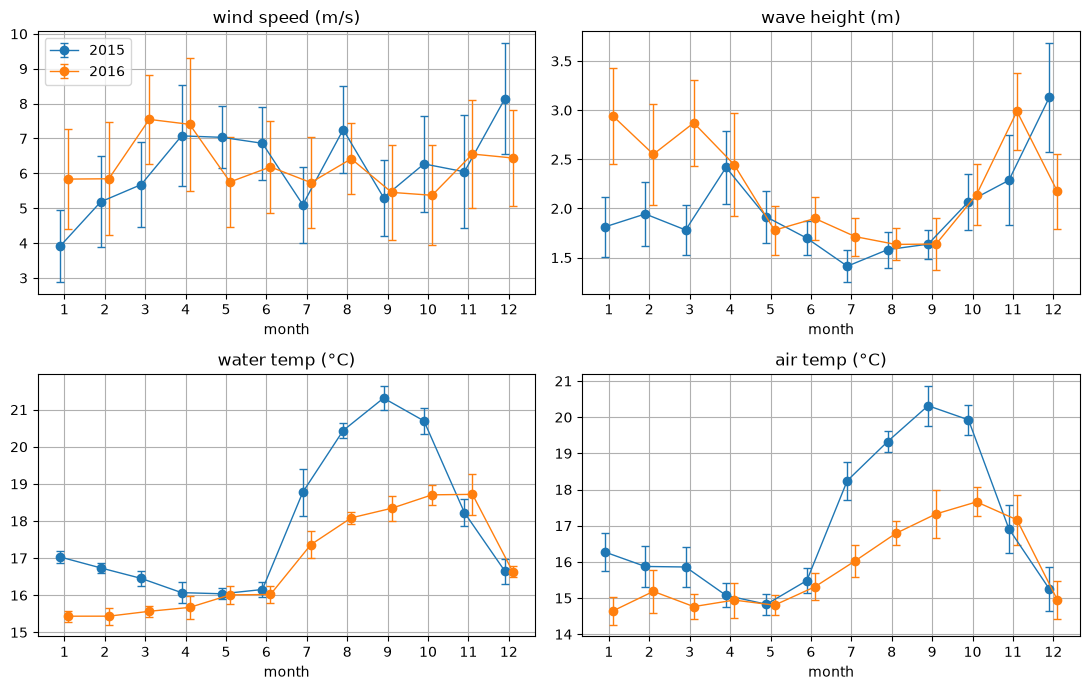

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, v in zip(axes.ravel(), missing):
    for yr, c, off in zip(years, ['C0', 'C1'], [-0.1, 0.1]):
        d = monthly[yr][v]
        ax.errorbar(d.index + off, d['mean'], yerr=d['sem_weekly'],
                    fmt='o-', color=c, capsize=3, lw=1, label=str(yr))
    ax.set_title(labels[v]); ax.set_xlabel('month')
    ax.set_xticks(range(1, 13)); ax.grid(True)
axes[0, 0].legend()
plt.tight_layout(); plt.show()


Solution for 2. There is a wide range of uncertainty, which I think is coming from variability/seasonal cycles, 2015-2016 was also an el nino, ENSO,  year so it good to note that as well, which might make sense of high temps in air and water. in the graph both wind speed and wave height have a wide variability in the beginning and end of the year;. wind speed seems to have a less obvious sin wave than the others, although you can still make it out. The Temp seems to be consistent with seasonal cycles, and as of now I haven't be able to clearly see the wave heigh pattern outside of it general Sin shape.


Starting on problem set 3.Least-squares fit. Treating the two years separately, least-squares fit a mean and an annual cycle to the four data records. What is the mean, and what is the amplitude of the annual cycle? (Total amplitude should be determined from the square root of the sum of the squares of the sine and cosine amplitudes.) Are the fitted coefficients similar for the two years?

Okay So I will have to do the Least-squares fit formula to account for the uncertainty in the graph. I will start there and plot the results. Using the formula coder for the leastsqs,Fit_annual for this. it is in the part of expanding the models to later find if these are orthoganol 

In [25]:
def fit_annual(month, y, sigma):
    t = month - 0.5                          # middle of each month, in months
    w = 2*np.pi*t/12                         # annual period = 12 months
    A = np.column_stack([np.ones_like(t), np.cos(w), np.sin(w)])
    Aw = A / sigma[:, None]                  # weight each row by 1/sigma
    yw = y / sigma
    x, *_ = np.linalg.lstsq(Aw, yw, rcond=None)
    xerr = np.sqrt(np.diag(np.linalg.inv(Aw.T @ Aw)))
    return x, xerr

I need to compare the data now to see if it fit better the wave.

In [ ]:
sem_col = 'sem_weekly'    

results = {}
for yr in years:
    print(f'--- {yr} ---')
    results[yr] = {}
    for v in missing:
        d = monthly[yr][v]
        month = d.index.values.astype(float)
        x, xerr = fit_annual(month, d['mean'].values, d[sem_col].values)
        amp = np.hypot(x[1], x[2])
        amp_err = np.sqrt((x[1]*xerr[1])**2 + (x[2]*xerr[2])**2) / amp
        results[yr][v] = dict(x=x, xerr=xerr, amp=amp, amp_err=amp_err)
        print(f'{labels[v]:18s} mean = {x[0]:6.2f} ± {xerr[0]:.2f}   '
              f'annual amp = {amp:5.2f} ± {amp_err:.2f}')

--- 2015 ---
wind speed (m/s)   mean =   5.96 ± 0.35   annual amp =  0.67 ± 0.48
wave height (m)    mean =   1.85 ± 0.08   annual amp =  0.29 ± 0.11
water temp (°C)    mean =  17.95 ± 0.07   annual amp =  2.33 ± 0.10
air temp (°C)      mean =  17.00 ± 0.13   annual amp =  2.58 ± 0.17
--- 2016 ---
wind speed (m/s)   mean =   6.23 ± 0.40   annual amp =  0.44 ± 0.57
wave height (m)    mean =   2.21 ± 0.10   annual amp =  0.57 ± 0.13
water temp (°C)    mean =  16.71 ± 0.06   annual amp =  1.54 ± 0.09
air temp (°C)      mean =  15.75 ± 0.12   annual amp =  1.37 ± 0.17


Overall it looks like these numbers did approch zero better than before and there is less variability than our first attempt. Lets plot to see if the it fits better. I didn't like the visuals of the graph so I adjusted it to be easier to understand.

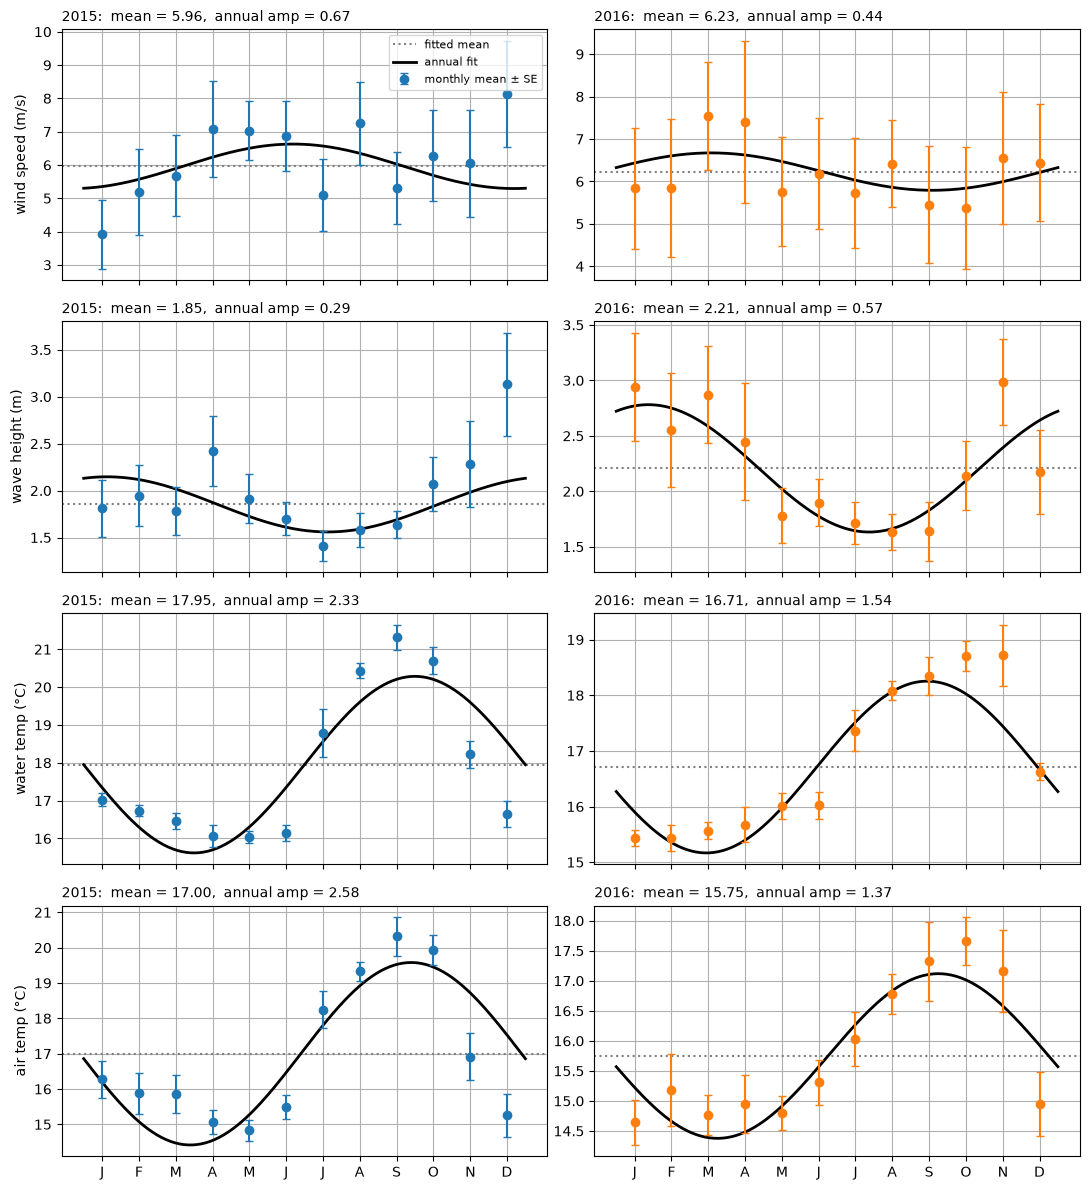

In [ ]:
tt = np.linspace(0, 12, 200)     
ww = 2*np.pi*tt/12
mletters = list('JFMAMJJASOND')

fig, axes = plt.subplots(4, 2, figsize=(11, 12), sharex=True)
for row, v in enumerate(missing):
    for col, yr in enumerate(years):
        ax = axes[row, col]
        d = monthly[yr][v]
        x = results[yr][v]['x']
        amp = results[yr][v]['amp']
        curve = x[0] + x[1]*np.cos(ww) + x[2]*np.sin(ww)

        ax.axhline(x[0], color='gray', ls=':', lw=1.5, label='fitted mean')
        ax.plot(tt, curve, 'k-', lw=2, label='annual fit')
        ax.errorbar(d.index - 0.5, d['mean'], yerr=d[sem_col], fmt='o',
                    color=f'C{col}', capsize=3, label='monthly mean ± SE')

        ax.set_title(f'{yr}:  mean = {x[0]:.2f},  annual amp = {amp:.2f}',
                     fontsize=10, loc='left')
        if col == 0:
            ax.set_ylabel(labels[v])
        ax.grid(True)

for ax in axes[-1]:
    ax.set_xticks(np.arange(0.5, 12, 1))
    ax.set_xticklabels(mletters)
axes[0, 0].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

In [28]:
print(f'{"variable":18s} {"Δmean/σ":>9s} {"Δamp/σ":>9s}')
for v in missing:
    r15, r16 = results[2015][v], results[2016][v]
    dm = (r16['x'][0] - r15['x'][0]) / np.hypot(r15['xerr'][0], r16['xerr'][0])
    da = (r16['amp'] - r15['amp']) / np.hypot(r15['amp_err'], r16['amp_err'])
    print(f'{labels[v]:18s} {dm:9.1f} {da:9.1f}')

variable             Δmean/σ    Δamp/σ
wind speed (m/s)         0.5      -0.3
wave height (m)          2.7       1.7
water temp (°C)        -13.2      -5.7
air temp (°C)           -6.9      -5.1


Solution for Problem 3. Looking at the annual cycle Amplitudes wind Speed mean and amp is within 1-Sigma. Meaning that that is expected and there is no variable cycle we are looking at here. But, Wave height and temperature do in fact have a annual cycle of note. When I compare the 2-years they do not appear similar. the amplitudes overall are far too different to say it was the same. This makes since since ENSO was that year, and there may have been more other factors but that is a large one; for this year anyways.

Getting started on problem set 4:
4.Least-squares fit a semi-annual cycle. Augment your annual cycle least squares fit with a semi-annual cycle. What is the amplitude of the semi-annual
cycle? Does the augmented fit give you a different annual cycle?
    On this one I will have to 1/2 the year and fit a wave function into this cos/sin then split this into 2. or if we wanted to spilt the hours into 12 hr days if there are waves/tidal currents might explain some of the variability on that side of the data. in any case i need to add t adds a cosine and sine at twice the frequency.

In [30]:
def fit_harm(month, y, sigma, nharm):
    t = month - 0.5                          # middle of each month, in months
    w = 2*np.pi*t/12                         # annual frequency
    cols = [np.ones_like(t)]                 # column of ones -> the mean
    for k in range(1, nharm + 1):
        cols += [np.cos(k*w), np.sin(k*w)]   # k=1 annual, k=2 semi-annual
    A = np.column_stack(cols)
    Aw = A / sigma[:, None]                  # weight each row by 1/sigma
    yw = y / sigma
    x, *_ = np.linalg.lstsq(Aw, yw, rcond=None)
    xerr = np.sqrt(np.diag(np.linalg.inv(Aw.T @ Aw)))
    return x, xerr, A

In [31]:
results2 = {}
for yr in years:
    print(f'--- {yr} ---')
    print(f'{"":18s} {"annual amp":>10s} {"annual amp":>11s} {"semi-annual amp":>18s}')
    print(f'{"":18s} {"(3.2)":>10s} {"(with semi)":>11s}')
    results2[yr] = {}
    for v in missing:
        d = monthly[yr][v]
        month = d.index.values.astype(float)
        x, xerr, A = fit_harm(month, d['mean'].values, d[sem_col].values, nharm=2)
        amp1 = np.hypot(x[1], x[2])
        amp2 = np.hypot(x[3], x[4])
        amp2_err = np.sqrt((x[3]*xerr[3])**2 + (x[4]*xerr[4])**2) / amp2
        results2[yr][v] = dict(x=x, xerr=xerr, amp1=amp1, amp2=amp2, amp2_err=amp2_err)
        print(f'{labels[v]:18s} {results[yr][v]["amp"]:10.2f} {amp1:11.2f} {amp2:12.2f} ± {amp2_err:.2f}')

--- 2015 ---
                   annual amp  annual amp    semi-annual amp
                        (3.2) (with semi)
wind speed (m/s)         0.67        0.51         0.84 ± 0.50
wave height (m)          0.29        0.29         0.26 ± 0.11
water temp (°C)          2.33        2.30         1.05 ± 0.10
air temp (°C)            2.58        2.28         1.18 ± 0.18
--- 2016 ---
                   annual amp  annual amp    semi-annual amp
                        (3.2) (with semi)
wind speed (m/s)         0.44        0.46         0.22 ± 0.57
wave height (m)          0.57        0.57         0.04 ± 0.13
water temp (°C)          1.54        1.66         0.53 ± 0.09
air temp (°C)            1.37        1.42         0.54 ± 0.17


With this new set of frequency; I am will re-plot it and see if the 6-month feq fits better. although it does look much more promising based on the annual means. 

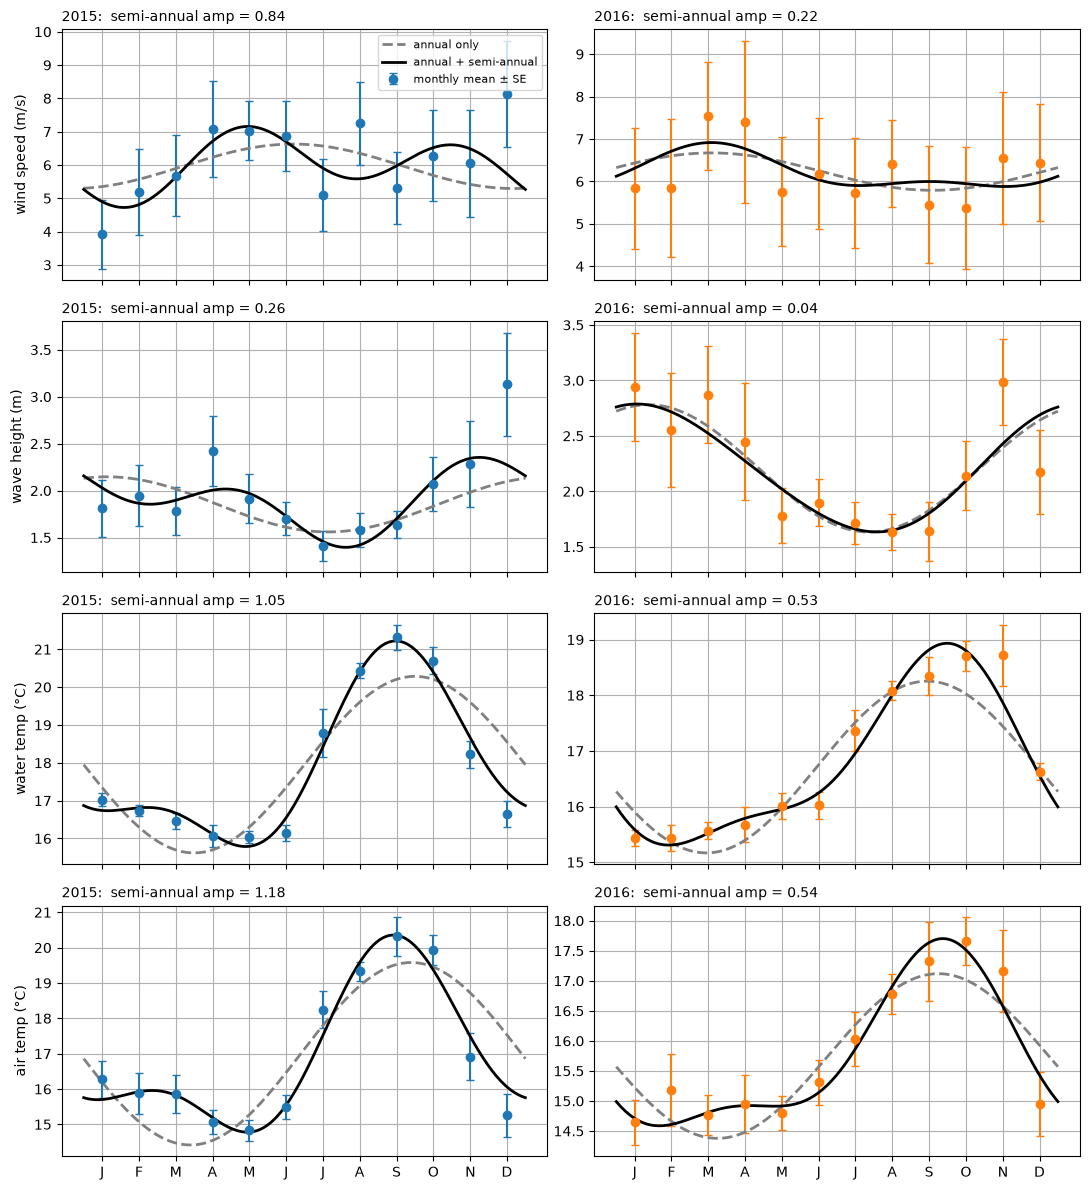

In [32]:
tt = np.linspace(0, 12, 200)
ww = 2*np.pi*tt/12
mletters = list('JFMAMJJASOND')

fig, axes = plt.subplots(4, 2, figsize=(11, 12), sharex=True)
for row, v in enumerate(missing):
    for col, yr in enumerate(years):
        ax = axes[row, col]
        d = monthly[yr][v]
        x1 = results[yr][v]['x']
        x2 = results2[yr][v]['x']
        fit1 = x1[0] + x1[1]*np.cos(ww) + x1[2]*np.sin(ww)
        fit2 = (x2[0] + x2[1]*np.cos(ww) + x2[2]*np.sin(ww)
                      + x2[3]*np.cos(2*ww) + x2[4]*np.sin(2*ww))

        ax.errorbar(d.index - 0.5, d['mean'], yerr=d[sem_col], fmt='o',
                    color=f'C{col}', capsize=3, label='monthly mean ± SE')
        ax.plot(tt, fit1, '--', color='gray', lw=2, label='annual only')
        ax.plot(tt, fit2, 'k-', lw=2, label='annual + semi-annual')
        ax.set_title(f'{yr}:  semi-annual amp = {results2[yr][v]["amp2"]:.2f}',
                     fontsize=10, loc='left')
        if col == 0:
            ax.set_ylabel(labels[v])
        ax.grid(True)

for ax in axes[-1]:
    ax.set_xticks(np.arange(0.5, 12, 1))
    ax.set_xticklabels(mletters)
axes[0, 0].legend(fontsize=8, loc='best')
plt.tight_layout()
plt.show()

Solution for problem set 4. I am not sure if I should have gotten a better fit, by adding the 6-month period or 2x frequency I was expecting to see a stronger response from the wave height. Given the example we did in class. Although the shape seems to go with the points It does not match as well as expected but the shape did improve a bit although there is a slight shift to the left.


Lets start on the mismatch problem set 5.I don't remember this well from class, so I will need to review first. 

I so this is looking at the two plots/data we proccessed and seeing how well they match or imporove as a metric so in the first part of the data we took the annual monthly mean and stddev. we found that there was a significate dev. in the data so we then move on to the leastsqs, we introduced a sin/cos to plot the fequancy and to see if that would fit our data better this seems to work a bit better but still needed imporvement. Finally, we took the wave and split it into 2-periods this had the largest imporvement to fitting the signal in the data so fat. now, the misfit will tell us how well this anaysis did and wether our singal of sin/cos to explain the varation and the pattern fits with what we were able to devrive from it. 

In [33]:
from scipy.stats import chi2 as chi2_dist

def chi2_fit(d, col, nharm):
    month = d.index.values.astype(float)
    x, xerr, A = fit_harm(month, d['mean'].values, d[col].values, nharm)
    resid = (d['mean'].values - A @ x) / d[col].values   # (y - Ax)/sigma, eq. (1) of the problem set
    return np.sum(resid**2), len(d) - A.shape[1]          # chi2, and dof = N - M

print('columns: chi2, dof, chi2/dof, p   (left: annual only, right: annual + semi-annual)')
for yr in years:
    print(f'--- {yr} ---')
    for v in missing:
        d = monthly[yr][v]
        c1, n1 = chi2_fit(d, 'sem_weekly', 1)
        c2, n2 = chi2_fit(d, 'sem_weekly', 2)
        print(f'{labels[v]:18s} {c1:8.1f} {n1:3d} {c1/n1:7.2f} {chi2_dist.sf(c1, n1):7.3f}   |   '
              f'{c2:8.1f} {n2:3d} {c2/n2:7.2f} {chi2_dist.sf(c2, n2):7.3f}')

columns: chi2, dof, chi2/dof, p   (left: annual only, right: annual + semi-annual)
--- 2015 ---
wind speed (m/s)        9.1   9    1.01   0.431   |        6.2   7    0.89   0.516
wave height (m)        10.9   9    1.21   0.285   |        5.6   7    0.79   0.593
water temp (°C)       141.4   9   15.71   0.000   |       16.3   7    2.33   0.022
air temp (°C)          49.3   9    5.48   0.000   |        8.5   7    1.21   0.293
--- 2016 ---
wind speed (m/s)        2.0   9    0.22   0.991   |        1.9   7    0.27   0.967
wave height (m)         6.6   9    0.73   0.681   |        6.5   7    0.93   0.485
water temp (°C)        39.2   9    4.35   0.000   |        8.7   7    1.24   0.277
air temp (°C)          13.1   9    1.45   0.160   |        3.5   7    0.50   0.832


In [34]:
crit = chi2_dist.ppf(0.95, 2)
print(f'95% critical value for 2 extra parameters: {crit:.2f}\n')
print(f'{"variable":18s} {"Δchi2":>8s} {"p":>8s}   verdict')
for yr in years:
    print(f'--- {yr} ---')
    for v in missing:
        d = monthly[yr][v]
        c1, n1 = chi2_fit(d, 'sem_weekly', 1)
        c2, n2 = chi2_fit(d, 'sem_weekly', 2)
        dc, dn = c1 - c2, n1 - n2                  # drop in misfit, and the 2 extra parameters
        p = chi2_dist.sf(dc, dn)
        print(f'{labels[v]:18s} {dc:8.1f} {p:8.3f}   {"improves" if p < 0.05 else "not significant"}')

95% critical value for 2 extra parameters: 5.99

variable              Δchi2        p   verdict
--- 2015 ---
wind speed (m/s)        2.9    0.238   not significant
wave height (m)         5.3    0.070   not significant
water temp (°C)       125.1    0.000   improves
air temp (°C)          40.8    0.000   improves
--- 2016 ---
wind speed (m/s)        0.2    0.921   not significant
wave height (m)         0.1    0.952   not significant
water temp (°C)        30.5    0.000   improves
air temp (°C)           9.5    0.009   improves


In [35]:
cols = ['sem_weekly', 'sem_daily', 'sem_all']
print(f'{"":18s} ' + ''.join(f'{c:>26s}' for c in cols))
print(f'{"":18s} ' + ''.join(f'{"annual":>13s}{"+semi":>13s}' for c in cols))
for yr in years:
    print(f'--- {yr}  (chi2) ---')
    for v in missing:
        d = monthly[yr][v]
        line = f'{labels[v]:18s} '
        for c in cols:
            line += f'{chi2_fit(d, c, 1)[0]:13.1f}{chi2_fit(d, c, 2)[0]:13.1f}'
        print(line)

                                   sem_weekly                 sem_daily                   sem_all
                          annual        +semi       annual        +semi       annual        +semi
--- 2015  (chi2) ---
wind speed (m/s)             9.1          6.2         63.5         43.4       1520.5       1039.4
wave height (m)             10.9          5.6         76.0         38.9       1729.1        877.4
water temp (°C)            141.4         16.3        989.9        114.2      23633.1       2728.1
air temp (°C)               49.3          8.5        345.1         59.3       8251.5       1419.5
--- 2016  (chi2) ---
wind speed (m/s)             2.0          1.9         14.2         13.0        337.2        310.0
wave height (m)              6.6          6.5         46.0         45.3       1094.2       1078.6
water temp (°C)             39.2          8.7        274.2         60.7       6503.2       1443.9
air temp (°C)               13.1          3.5         91.5         24.7     

Solution for 5.  
    I think wind and wave fit well; but, because of the variability of the temp the analysis didn't account well perhaps if i had used the 4-years instead of just the two years I would have gotten a better result; like it was said more data is the key. I think this would using the wrong model in this case one that accounts for ENSO would have been the right choice. I think using 1 sample a day the error bars would haven gotten much larger; but the wave function perhaps would have fit better but more errors. 

    End of Hw3